# Lab 2 — Ciclo de treino, vazamento e métricas
**Individual · 1,0 ponto na AV1 · 08/10/2026 · horário da atividade no Classroom**

Leia `ENUNCIADO.pdf` antes de preencher. A base comum está incluída; não é necessário usar o banco do projeto.

O notebook executa a preparação e um teste pequeno de ambiente. Nas atividades avaliadas, complete os **TODO** e substitua as mensagens de pendência por resultados. Não há métricas pré-medidas para copiar.

Ordem: preparação → B2 → A → C → D7 → D4–D6 → avaliação final → relatório.

## 0. Ambiente e pasta
No Colab, extraia o ZIP conforme o enunciado e execute `%cd /content/classroom-lab-02` antes da próxima célula. Localmente, abra este notebook na pasta extraída. CPU é suficiente.

In [1]:
from pathlib import Path
import sys, copy, time, json, platform, importlib.metadata
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset, Subset
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, precision_recall_curve, auc,
                             average_precision_score, brier_score_loss)
from sklearn.calibration import calibration_curve
from apoio import FEATURES, carregar_base, fixar_semente, criar_modelo
from apoio import treinar_epoca, avaliar_perda, obter_escores

SEED = 42
fixar_semente(SEED)
DISPOSITIVO = 'cpu'
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0])
for pacote in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'torch']:
    print(pacote, importlib.metadata.version(pacote))

def descrever_cpu():
    try:
        for linha in Path('/proc/cpuinfo').read_text().splitlines():
            if linha.startswith('model name'):
                return linha.split(':', 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()

EQUIPAMENTO = f'{descrever_cpu()} | {platform.system()} | threads torch={torch.get_num_threads()}'
print('Sistema:', platform.platform())
print('Equipamento:', EQUIPAMENTO, '| dispositivo:', DISPOSITIVO, '| semente:', SEED)

Python: 3.13.16
numpy 2.5.4
pandas 3.0.6
scikit-learn 1.9.1
matplotlib 3.11.2
torch 2.14.1+cpu
Sistema: Linux-6.12.76-linuxkit-aarch64-with-glibc2.41
Equipamento: aarch64 | Linux | threads torch=10 | dispositivo: cpu | semente: 42


### Leitura e conferência da base
`carregar_base` lê o CSV com `;`, confere sua integridade e cria o alvo e os identificadores de controle. As únicas entradas permitidas estão em `FEATURES`. Não aprende média, desvio, pesos ou partições.

Ver as contagens do arquivo não é treinar um modelo. Depois da B2, o teste principal deve permanecer fora das decisões e dos experimentos de erro.

In [2]:
amostras = carregar_base()
print(amostras.head().to_string(index=False))
print('\nLinhas:', len(amostras), '| características:', len(FEATURES))
print('Classe positiva:', int(amostras.alvo.sum()), '| proporção:', amostras.alvo.mean())
print('Perfis distintos:', amostras.grupo_perfil.nunique())
assert set(FEATURES).isdisjoint({'quality', 'alvo', 'id_linha', 'grupo_perfil'})

 fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density   pH  sulphates  alcohol  quality  alvo  id_linha         grupo_perfil
           7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978 3.51       0.56      9.4        5     0         0 16231909345439519184
           7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968 3.20       0.68      9.8        5     0         1  8814798900776851426
           7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970 3.26       0.65      9.8        5     0         2 16179437306182617678
          11.2              0.28         0.56             1.9      0.075                 17.0                  60.0   0.9980 3.16       0.58      9.8        6     0         3  8450966096714587765
           7.4      

### Exemplo mínimo: o que faz uma atualização
O bloco a seguir usa **quatro observações artificiais com duas entradas**, apenas para conferir instalação e formas. Não usa Wine Quality, não mede generalização e não atende às partes avaliadas. Um logit é transformado em escore por sigmoide só ao obter previsões; a perda recebe o logit.

In [3]:
x_exemplo = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_exemplo = torch.tensor([0., 0., 0., 1.])
exemplo_loader = DataLoader(TensorDataset(x_exemplo, y_exemplo), batch_size=2)
exemplo_modelo = criar_modelo(2).to(DISPOSITIVO)
exemplo_otimizador = torch.optim.Adam(exemplo_modelo.parameters(), lr=0.001)
exemplo_perda = treinar_epoca(exemplo_modelo, exemplo_loader, exemplo_otimizador,
                              nn.BCEWithLogitsLoss(), DISPOSITIVO)
print('Teste de ambiente concluído. Perda de treino artificial:', exemplo_perda)
del exemplo_modelo, exemplo_loader, exemplo_otimizador
fixar_semente(SEED)

Teste de ambiente concluído. Perda de treino artificial: 0.7283297479152679


## B2. Separe antes de normalizar
Implemente aproximadamente 60/20/20, conservando `grupo_perfil` em uma única partição. Use uma semente declarada. Consulte `GroupShuffleSplit`; proporções de grupos não garantem as mesmas proporções de linhas.

Retorne um dicionário com `treino`, `validacao`, `teste`, cada qual contendo um DataFrame. Mostre cobertura, interseção de linhas e perfis, contagens e classes. Não use IDs como características.

In [4]:
def dividir_por_perfil(df, semente=42):
    """Separa ~60/20/20 mantendo cada `grupo_perfil` inteiro em uma única partição.

    1º corte: GroupShuffleSplit reserva 20% dos GRUPOS para o teste.
    2º corte: dos grupos restantes, 25% vão para a validação (0,25 × 0,80 = 0,20).
    As proporções da API referem-se a grupos; a fração de linhas pode variar um pouco.
    O alvo não é usado para formar grupos nem para estratificar.
    """
    gss_teste = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=semente)
    idx_dev, idx_teste = next(gss_teste.split(df, groups=df['grupo_perfil']))
    dev = df.iloc[idx_dev]
    gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=semente)
    idx_tr, idx_val = next(gss_val.split(dev, groups=dev['grupo_perfil']))
    return {
        'treino': dev.iloc[idx_tr].reset_index(drop=True),
        'validacao': dev.iloc[idx_val].reset_index(drop=True),
        'teste': df.iloc[idx_teste].reset_index(drop=True),
    }

particoes_grupo = dividir_por_perfil(amostras, SEED)

# ---- feita antes de qualquer modelo  ----
tabela_b2 = pd.DataFrame([{
    'conjunto': nome,
    'linhas': len(p),
    'fracao_linhas': round(len(p) / len(amostras), 4),
    'positivos': int(p.alvo.sum()),
    'negativos': int((p.alvo == 0).sum()),
    'proporcao_positiva': round(p.alvo.mean(), 4),
    'perfis_distintos': p.grupo_perfil.nunique(),
    'repeticoes_internas': len(p) - p.grupo_perfil.nunique(),
} for nome, p in particoes_grupo.items()])
print(tabela_b2.to_string(index=False))

ids = {n: set(p.id_linha) for n, p in particoes_grupo.items()}
perfis = {n: set(p.grupo_perfil) for n, p in particoes_grupo.items()}
auditoria_b2 = pd.DataFrame([{
    'par': f'{a} x {b}',
    'linhas_em_comum': len(ids[a] & ids[b]),
    'perfis_em_comum': len(perfis[a] & perfis[b]),
} for a, b in combinations(particoes_grupo, 2)])
print('\n' + auditoria_b2.to_string(index=False))

soma_linhas = sum(len(p) for p in particoes_grupo.values())
cobertura_total = set().union(*ids.values()) == set(amostras.id_linha)
print(f'\nSoma das linhas: {soma_linhas} de {len(amostras)} | cobertura de todos os id_linha: {cobertura_total}')
assert soma_linhas == len(amostras) and cobertura_total
assert (auditoria_b2[['linhas_em_comum', 'perfis_em_comum']] == 0).all().all()
assert all(set(p.alvo.unique()) == {0, 1} for p in particoes_grupo.values())
# Prova de que mesmo perfil não tem alvos conflitantes (confere o dicionário):
print('Perfis com alvo conflitante na base:', int((amostras.groupby('grupo_perfil').alvo.nunique() > 1).sum()))
tabela_b2.to_csv(RESULTADOS / 'b2_particoes.csv', index=False)
auditoria_b2.to_csv(RESULTADOS / 'b2_intersecoes.csv', index=False)

 conjunto  linhas  fracao_linhas  positivos  negativos  proporcao_positiva  perfis_distintos  repeticoes_internas
   treino     961         0.6010        139        822              0.1446               815                  146
validacao     318         0.1989         33        285              0.1038               272                   46
    teste     320         0.2001         45        275              0.1406               272                   48

               par  linhas_em_comum  perfis_em_comum
treino x validacao                0                0
    treino x teste                0                0
 validacao x teste                0                0

Soma das linhas: 1599 de 1599 | cobertura de todos os id_linha: True
Perfis com alvo conflitante na base: 0


### B1. Cinco cenários
Responda no README aos cinco cenários do enunciado: avaliações de produtos; turbinas; spam; radiografias; transações. Declare o uso e as hipóteses. Na quinta resposta, discuta tempo e identidade dos clientes. As respostas não precisam de bancos adicionais.

## A1. Dataset próprio
Implemente a classe abaixo com as estatísticas opcionais. Aprenda média/desvio somente no treino e passe-os aos outros conjuntos. Trate desvio zero, preserve o alinhamento e devolva `float32`: X `[11]`, y escalar. Mostre as verificações solicitadas.

In [5]:
class DatasetVinho(Dataset):
    """Dataset tabular de UMA partição do Red Wine Quality, já padronizado."""

    def __init__(self, df, features, media=None, desvio=None):
        """Prepara X padronizado e y a partir de `df`.

        - `features`: lista das 11 entradas permitidas (nunca quality/alvo/ids).
        - Sem `media`/`desvio` (uso no TREINO): aprende-os com as linhas deste `df`.
          Convenção: desvio populacional, ddof=0 (mesma do StandardScaler).
        - Com `media`/`desvio` (VALIDAÇÃO e TESTE): reutiliza exatamente os valores
          recebidos, que devem vir do treino. Nada é reaprendido aqui.
        - Desvio zero ou não finito é trocado por 1: a coluna fica apenas centrada,
          sem divisão por zero (`self.colunas_desvio_zero` registra quais).
        Os tensores float32 são criados uma vez, na mesma ordem das linhas de `df`.
        """
        if (media is None) != (desvio is None):
            raise ValueError('Forneça média e desvio juntos, ou nenhum dos dois.')
        proibidas = {'quality', 'alvo', 'id_linha', 'grupo_perfil'}
        if proibidas & set(features):
            raise ValueError('Colunas de alvo/controle não podem ser entradas.')
        self.features = list(features)
        x = df[self.features].to_numpy(dtype=np.float64)
        if media is None:
            media, desvio = x.mean(axis=0), x.std(axis=0, ddof=0)
            self.origem_estatisticas = 'aprendidas nesta partição (treino)'
        else:
            self.origem_estatisticas = 'recebidas do treino'
        media = np.asarray(media, dtype=np.float64).copy()
        desvio = np.asarray(desvio, dtype=np.float64).copy()
        self.colunas_desvio_zero = [f for f, d in zip(self.features, desvio) if not np.isfinite(d) or d == 0]
        desvio = np.where(np.isfinite(desvio) & (desvio > 0), desvio, 1.0)
        self.media, self.desvio = media, desvio
        self.X = torch.tensor((x - media) / desvio, dtype=torch.float32)
        self.y = torch.tensor(df['alvo'].to_numpy(), dtype=torch.float32)
        self.id_linha = df['id_linha'].to_numpy().copy()
        if not torch.isfinite(self.X).all():
            raise ValueError('Valores não finitos após a padronização.')

    def __len__(self):
        """Número de observações (linhas) da partição."""
        return len(self.y)

    def __getitem__(self, indice):
        """Devolve (X [11] float32, y escalar float32) da mesma linha `indice`."""
        return self.X[indice], self.y[indice]


ds_treino = DatasetVinho(particoes_grupo['treino'], FEATURES)
ds_validacao = DatasetVinho(particoes_grupo['validacao'], FEATURES, ds_treino.media, ds_treino.desvio)
ds_teste = DatasetVinho(particoes_grupo['teste'], FEATURES, ds_treino.media, ds_treino.desvio)

for nome, ds in [('treino', ds_treino), ('validacao', ds_validacao), ('teste', ds_teste)]:
    x0, y0 = ds[0]
    print(f'{nome:9s} len={len(ds):4d} | X[0] {tuple(x0.shape)} {x0.dtype} | y[0] {tuple(y0.shape)} {y0.dtype} '
          f'| NaN/inf: {int((~torch.isfinite(ds.X)).sum())} | estatísticas: {ds.origem_estatisticas}')
xb, yb = next(iter(DataLoader(ds_treino, batch_size=8)))
print('Lote de 8:', tuple(xb.shape), xb.dtype, '|', tuple(yb.shape), yb.dtype)
print('Colunas com desvio zero:', ds_treino.colunas_desvio_zero or 'nenhuma')

# Evidência de que validação/teste usaram as estatísticas do treino
assert np.array_equal(ds_validacao.media, ds_treino.media) and np.array_equal(ds_teste.desvio, ds_treino.desvio)
estat = pd.DataFrame({
    'media_treino': ds_treino.media,
    'desvio_treino': ds_treino.desvio,
    'media_propria_validacao': particoes_grupo['validacao'][FEATURES].mean().to_numpy(),
    'media_padronizada_treino': ds_treino.X.mean(0).numpy(),
    'media_padronizada_validacao': ds_validacao.X.mean(0).numpy(),
    'media_padronizada_teste': ds_teste.X.mean(0).numpy(),
}, index=FEATURES).round(4)
print(estat.to_string())
print('Treino padronizado tem média ~0 e desvio ~1; validação/teste não precisam ter (não é critério).')

# Alinhamento: X reconstruído e y voltam exatamente à linha original
i = 7
x_rec = ds_validacao.X[i].double().numpy() * ds_treino.desvio + ds_treino.media
assert np.allclose(x_rec, particoes_grupo['validacao'].loc[i, FEATURES].to_numpy(float), atol=1e-4)
assert ds_validacao.y[i].item() == particoes_grupo['validacao'].loc[i, 'alvo']
print('Alinhamento X/y conferido na linha', i, 'da validação (id_linha =', ds_validacao.id_linha[i], ')')
estat.to_csv(RESULTADOS / 'a1_estatisticas.csv')

treino    len= 961 | X[0] (11,) torch.float32 | y[0] () torch.float32 | NaN/inf: 0 | estatísticas: aprendidas nesta partição (treino)
validacao len= 318 | X[0] (11,) torch.float32 | y[0] () torch.float32 | NaN/inf: 0 | estatísticas: recebidas do treino
teste     len= 320 | X[0] (11,) torch.float32 | y[0] () torch.float32 | NaN/inf: 0 | estatísticas: recebidas do treino
Lote de 8: (8, 11) torch.float32 | (8,) torch.float32
Colunas com desvio zero: nenhuma
                      media_treino  desvio_treino  media_propria_validacao  media_padronizada_treino  media_padronizada_validacao  media_padronizada_teste
fixed acidity               8.2957         1.7030                   8.4513                       0.0                       0.0913                  -0.0206
volatile acidity            0.5224         0.1809                   0.5467                       0.0                       0.1343                   0.0162
citric acid                 0.2707         0.1918                   0.2740  

## A2. Três DataLoaders
Preencha a tabela de parâmetros no README e crie os carregadores. Na avaliação não descarte observações. `obter_escores` devolve rótulos e escores percorridos juntos, evitando confundir uma ordem de rótulos com outra de previsões.

In [6]:
LOTE_TREINO, LOTE_AVALIACAO = 64, 256
gerador_treino = torch.Generator().manual_seed(SEED)   # embaralhamento reprodutível
loader_treino = DataLoader(ds_treino, batch_size=LOTE_TREINO, shuffle=True,
                           drop_last=False, num_workers=0, generator=gerador_treino)
loader_validacao = DataLoader(ds_validacao, batch_size=LOTE_AVALIACAO, shuffle=False,
                              drop_last=False, num_workers=0)
loader_teste = DataLoader(ds_teste, batch_size=LOTE_AVALIACAO, shuffle=False,
                          drop_last=False, num_workers=0)

tabela_a2 = pd.DataFrame([
    {'conjunto': n, 'batch_size': l.batch_size, 'shuffle': isinstance(l.sampler, torch.utils.data.RandomSampler),
     'drop_last': l.drop_last, 'num_workers': l.num_workers, 'exemplos': len(l.dataset),
     'passos': len(l), 'tamanho_ultimo_lote': len(l.dataset) - (len(l) - 1) * l.batch_size}
    for n, l in [('treino', loader_treino), ('validacao', loader_validacao), ('teste', loader_teste)]])
print(tabela_a2.to_string(index=False))
assert sum(len(y) for _, y in loader_validacao) == len(ds_validacao)   # nada descartado
assert sum(len(y) for _, y in loader_teste) == len(ds_teste)

# Medição antes de alegar algo sobre num_workers: tempo de percorrer o loader de treino
def tempo_percorrer(nw, reps=3):
    ld = DataLoader(ds_treino, batch_size=LOTE_TREINO, shuffle=True, num_workers=nw,
                    generator=torch.Generator().manual_seed(SEED))
    ts = []
    for _ in range(reps + 1):                       # 1ª passagem = aquecimento
        t0 = time.perf_counter()
        for _ in ld:
            pass
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts[1:]))

tempos_workers = {nw: tempo_percorrer(nw) for nw in [0, 2]}
for nw, t in tempos_workers.items():
    print(f'num_workers={nw}: mediana {t*1000:.2f} ms por passagem completa do treino')

 conjunto  batch_size  shuffle  drop_last  num_workers  exemplos  passos  tamanho_ultimo_lote
   treino          64     True      False            0       961      16                    1
validacao         256    False      False            0       318       2                   62
    teste         256    False      False            0       320       2                   64


num_workers=0: mediana 1.23 ms por passagem completa do treino
num_workers=2: mediana 22.93 ms por passagem completa do treino


## A3. Tempo de uma época
Teste os quatro lotes com a rede de apoio **sem BatchNorm**. Controle o estado inicial, novo otimizador, dados e dispositivo; faça aquecimento antes de medir. Percorra o treino inteiro. Use `treinar_epoca`, `time.perf_counter` e, se necessário, sincronização CUDA. Registre repetições e mediana; explique o resultado, inclusive se não for monotônico.

repeticao   rep1_s  rep2_s  rep3_s  mediana_s  passos  ms_por_passo  us_por_exemplo  ganho_vs_lote_anterior
batch_size                                                                                                 
1           0.3971  0.3946  0.3816     0.3946     961        0.4106        410.6266                     NaN
8           0.0723  0.0710  0.0717     0.0717     121        0.5927         74.6231                  5.5027
64          0.0105  0.0105  0.0111     0.0105      16        0.6582         10.9581                  6.8099
512         0.0023  0.0024  0.0022     0.0023       2        1.1539          2.4015                  4.5630


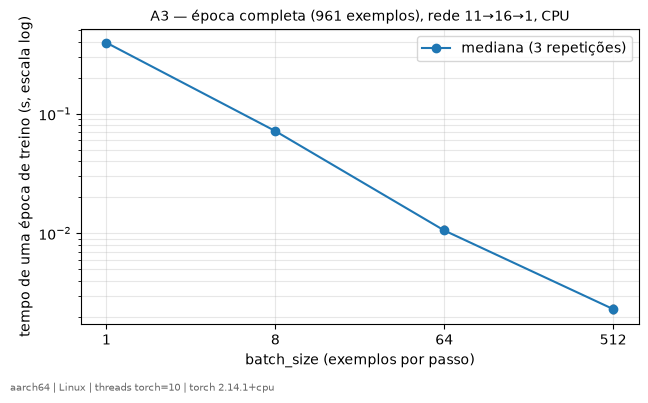

In [7]:
tamanhos_lote = [1, 8, 64, 512]
REPETICOES = 3
tempos = []
fixar_semente(SEED)
estado_inicial_a3 = copy.deepcopy(criar_modelo(11).state_dict())   # mesmo ponto de partida para todos

def medir_epoca(tamanho_lote):
    """Uma época completa (previsão, perda, retropropagação, atualização) a partir do mesmo estado."""
    modelo = criar_modelo(11).to(DISPOSITIVO)           # sem BatchNorm
    modelo.load_state_dict(estado_inicial_a3)
    otimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)   # otimizador novo
    loader = DataLoader(ds_treino, batch_size=tamanho_lote, shuffle=True, drop_last=False,
                        num_workers=0, generator=torch.Generator().manual_seed(SEED))
    t0 = time.perf_counter()
    perda = treinar_epoca(modelo, loader, otimizador, nn.BCEWithLogitsLoss(), DISPOSITIVO)
    segundos = time.perf_counter() - t0
    return segundos, len(loader), perda

for b in tamanhos_lote:
    medir_epoca(b)                                     # aquecimento, fora da medição
    for rep in range(1, REPETICOES + 1):
        s, passos, perda = medir_epoca(b)
        tempos.append({'batch_size': b, 'repeticao': rep, 'segundos': s, 'passos': passos,
                       'exemplos': len(ds_treino), 'perda_treino_epoca': perda})

tabela_tempos = pd.DataFrame(tempos)
resumo_a3 = (tabela_tempos.pivot(index='batch_size', columns='repeticao', values='segundos')
             .rename(columns=lambda r: f'rep{r}_s'))
resumo_a3['mediana_s'] = tabela_tempos.groupby('batch_size').segundos.median()
resumo_a3['passos'] = tabela_tempos.groupby('batch_size').passos.first()
resumo_a3['ms_por_passo'] = 1000 * resumo_a3.mediana_s / resumo_a3.passos
resumo_a3['us_por_exemplo'] = 1e6 * resumo_a3.mediana_s / len(ds_treino)
resumo_a3['ganho_vs_lote_anterior'] = resumo_a3.mediana_s.shift(1) / resumo_a3.mediana_s
print(resumo_a3.round(4).to_string())
tabela_tempos.to_csv(RESULTADOS / 'a3_tempos_brutos.csv', index=False)
resumo_a3.round(6).to_csv(RESULTADOS / 'a3_tempos_resumo.csv')

fig, ax = plt.subplots(figsize=(6.5, 4))
for b, g in tabela_tempos.groupby('batch_size'):
    ax.scatter([b] * len(g), g.segundos, color='0.6', s=14, zorder=2)
ax.plot(resumo_a3.index, resumo_a3.mediana_s, marker='o', zorder=3, label='mediana (3 repetições)')
ax.set_xscale('log', base=2); ax.set_yscale('log')
ax.set_xticks(tamanhos_lote, [str(b) for b in tamanhos_lote])
ax.set_xlabel('batch_size (exemplos por passo)')
ax.set_ylabel('tempo de uma época de treino (s, escala log)')
ax.set_title(f'A3 — época completa ({len(ds_treino)} exemplos), rede 11→16→1, CPU', fontsize=10)
fig.text(0.01, 0.01, EQUIPAMENTO + f' | torch {torch.__version__}', fontsize=7, color='0.4')
ax.legend(); ax.grid(alpha=.3, which='both')
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(RESULTADOS / 'a3_tempo_por_lote.png', dpi=150)
plt.show()

## A4. BatchNorm com último lote 1
Use um subconjunto de 65 observações do treino e lote 64, ou outra condição equivalente. Confirme o resto. Use `criar_modelo(11, batchnorm=True)`, modo de treino e `drop_last=False`. Capture especificamente o erro esperado, mostre sua mensagem e depois execute a correção que escolheu. Preserve as outras partes do notebook.

In [8]:
LOTE_BN = 64
indices_bn = torch.randperm(len(ds_treino), generator=torch.Generator().manual_seed(SEED))[:65].tolist()
ds_bn = Subset(ds_treino, indices_bn)            # só linhas do TREINO; demonstração apenas
resto = len(ds_bn) % LOTE_BN
print(f'Subconjunto: {len(ds_bn)} observações | lote {LOTE_BN} | resto {resto}')
assert resto == 1

fixar_semente(SEED)
modelo_bn = criar_modelo(11, batchnorm=True).to(DISPOSITIVO)
estado_bn_inicial = copy.deepcopy(modelo_bn.state_dict())
criterio_bn = nn.BCEWithLogitsLoss()
loader_bn_falho = DataLoader(ds_bn, batch_size=LOTE_BN, shuffle=False, drop_last=False)
print('Tamanhos dos lotes com drop_last=False:', [len(y) for _, y in loader_bn_falho])

mensagem_bn = None
try:
    treinar_epoca(modelo_bn, loader_bn_falho, torch.optim.Adam(modelo_bn.parameters(), lr=1e-3),
                  criterio_bn, DISPOSITIVO)        # treinar_epoca chama modelo.train()
except ValueError as erro:                         # captura específica deste experimento
    if 'Expected more than 1 value per channel' not in str(erro):
        raise
    mensagem_bn = str(erro)
    print('ERRO ESPERADO capturado (lote de tamanho 1 em modo train):\n ', mensagem_bn)
else:
    raise AssertionError('O erro esperado de BatchNorm não ocorreu.')

# Correção escolhida: drop_last=True no carregador de TREINO + shuffle=True.
# Custo: 1 observação (65 % 64) fica fora de cada época; com embaralhamento, a excluída muda a cada época.
modelo_bn.load_state_dict(estado_bn_inicial)       # recomeça do mesmo estado (1º lote já havia atualizado)
otim_bn = torch.optim.Adam(modelo_bn.parameters(), lr=1e-3)
loader_bn_corrigido = DataLoader(ds_bn, batch_size=LOTE_BN, shuffle=True, drop_last=True,
                                 generator=torch.Generator().manual_seed(SEED))
vistos = set()
for epoca in range(1, 4):
    perda = treinar_epoca(modelo_bn, loader_bn_corrigido, otim_bn, criterio_bn, DISPOSITIVO)
    print(f'Correção — época {epoca}: perda {perda:.4f} | passos {len(loader_bn_corrigido)} '
          f'| exemplos usados {len(loader_bn_corrigido) * LOTE_BN} de {len(ds_bn)}')

# Alternativa sem descarte (comparação): escolher um lote que não deixe resto 1 (65 % 33 = 32).
loader_bn_alt = DataLoader(ds_bn, batch_size=33, shuffle=True, drop_last=False,
                           generator=torch.Generator().manual_seed(SEED))
print('Alternativa lote 33 → tamanhos:', [len(y) for _, y in loader_bn_alt],
      '| perda:', round(treinar_epoca(modelo_bn, loader_bn_alt, otim_bn, criterio_bn, DISPOSITIVO), 4))
# Avaliação com drop_last=False continua possível: em eval() o BatchNorm usa as médias móveis.
loader_bn_eval = DataLoader(ds_bn, batch_size=LOTE_BN, shuffle=False, drop_last=False)
print('Perda em modo eval com último lote de 1 (sem erro):', round(avaliar_perda(modelo_bn, loader_bn_eval, criterio_bn), 4))

Subconjunto: 65 observações | lote 64 | resto 1
Tamanhos dos lotes com drop_last=False: [64, 1]
ERRO ESPERADO capturado (lote de tamanho 1 em modo train):
  Expected more than 1 value per channel when training, got input size torch.Size([1, 16])
Correção — época 1: perda 0.6505 | passos 1 | exemplos usados 64 de 65
Correção — época 2: perda 0.6462 | passos 1 | exemplos usados 64 de 65
Correção — época 3: perda 0.6435 | passos 1 | exemplos usados 64 de 65
Alternativa lote 33 → tamanhos: [33, 32] | perda: 0.6317
Perda em modo eval com último lote de 1 (sem erro): 0.6296


## C. Dois mecanismos de vazamento
Selecione duas formas; pelo menos uma entre 2/4/7 e uma com dados reais. Um caminho acessível é 1 e 2, usando a base incluída. **Formas 1–7 estão descritas no enunciado.**

Trabalhe apenas com as linhas principais de treino + validação. Crie partições internas `c_...`. Não use a partição principal de teste. Defina o modelo, a métrica e as condições antes de executar o par incorreto/corrigido. Se usar a forma 7, reserve desde o início os quatro conjuntos internos e compare seleções com orçamento igual.

In [9]:
# ---------- Desenho declarado ANTES de executar qualquer par incorreto/corrigido ----------
# Dados: somente treino + validação da B2. O teste principal não entra nesta parte.
# Partição interna: GroupShuffleSplit por grupo_perfil, 75% c_treino / 25% c_avaliacao, semente 42.
# Modelo: criar_modelo (11→16→1, sem BatchNorm), Adam lr=1e-3, BCEWithLogitsLoss, lote 64,
#         60 épocas fixas (sem parada antecipada, para não usar c_avaliacao na seleção).
# Métrica principal: acurácia com corte 0,5 em c_avaliacao; secundária: AUC-ROC.
# Sementes de inicialização: [0, 1, 2, 3, 4], fixadas antes; reportamos média e todas as diferenças.
c_desenvolvimento = pd.concat([particoes_grupo['treino'], particoes_grupo['validacao']], ignore_index=True)
assert set(c_desenvolvimento.id_linha).isdisjoint(set(particoes_grupo['teste'].id_linha))
c_gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
c_i_tr, c_i_av = next(c_gss.split(c_desenvolvimento, groups=c_desenvolvimento.grupo_perfil))
c_treino = c_desenvolvimento.iloc[c_i_tr].reset_index(drop=True)
c_avaliacao = c_desenvolvimento.iloc[c_i_av].reset_index(drop=True)
print(f'c_desenvolvimento={len(c_desenvolvimento)} | c_treino={len(c_treino)} (pos {c_treino.alvo.mean():.3f}) '
      f'| c_avaliacao={len(c_avaliacao)} (pos {c_avaliacao.alvo.mean():.3f}) '
      f'| perfis em comum={len(set(c_treino.grupo_perfil) & set(c_avaliacao.grupo_perfil))}')
C_SEMENTES, C_EPOCAS, C_LOTE, C_LR = [0, 1, 2, 3, 4], 60, 64, 1e-3

def c_padronizar(df_ajuste, colunas, *dfs):
    """Aprende média/desvio (ddof=0) em df_ajuste e aplica a cada df de dfs."""
    m = df_ajuste[colunas].to_numpy(float).mean(0)
    d = df_ajuste[colunas].to_numpy(float).std(0)
    d = np.where(d > 0, d, 1.0)
    return [torch.tensor((df[colunas].to_numpy(float) - m) / d, dtype=torch.float32) for df in dfs]

def c_treinar_avaliar(x_tr, y_tr, x_av, y_av, semente):
    fixar_semente(semente)
    c_modelo = criar_modelo(x_tr.shape[1]).to(DISPOSITIVO)
    c_otim = torch.optim.Adam(c_modelo.parameters(), lr=C_LR)
    c_loader = DataLoader(TensorDataset(x_tr, y_tr), batch_size=C_LOTE, shuffle=True,
                          generator=torch.Generator().manual_seed(semente))
    for _ in range(C_EPOCAS):
        treinar_epoca(c_modelo, c_loader, c_otim, nn.BCEWithLogitsLoss(), DISPOSITIVO)
    y, s = obter_escores(c_modelo, DataLoader(TensorDataset(x_av, y_av), batch_size=512), DISPOSITIVO)
    return {'acuracia': accuracy_score(y, s >= 0.5), 'auc_roc': roc_auc_score(y, s), 'escores': s, 'rotulos': y}

def c_rotulos(df):
    return torch.tensor(df.alvo.to_numpy(), dtype=torch.float32)

c_por_semente = []
def c_registrar(forma, versao, x_tr, y_tr, x_av, y_av):
    for sem in C_SEMENTES:
        r = c_treinar_avaliar(x_tr, y_tr, x_av, y_av, sem)
        c_por_semente.append({'forma': forma, 'versao': versao, 'semente': sem,
                              'acuracia': r['acuracia'], 'auc_roc': r['auc_roc']})

c_desenvolvimento=1279 | c_treino=961 (pos 0.145) | c_avaliacao=318 (pos 0.104) | perfis em comum=0


### C — Forma 2: alvo (ou derivado dele) entre as características
**Informação protegida:** `quality`, a nota sensorial da qual o alvo é derivado (`alvo = quality >= 7`). Ela só existe depois da avaliação sensorial, que é justamente o que o sistema quer antecipar.
**Onde atravessa a fronteira:** na montagem da matriz de entrada. **Transformação declarada:** a versão incorreta acrescenta a coluna original `quality` como 12ª entrada (padronizada com as estatísticas de `c_treino`). A versão corrigida usa só as 11 `FEATURES`. Mesmas partições internas, sementes, épocas e otimizador.

In [10]:
y_ctr, y_cav = c_rotulos(c_treino), c_rotulos(c_avaliacao)
# INCORRETO (forma 2): quality entra como característica
x_tr_err, x_av_err = c_padronizar(c_treino, FEATURES + ['quality'], c_treino, c_avaliacao)
c_registrar('2 - alvo nas entradas', 'incorreto', x_tr_err, y_ctr, x_av_err, y_cav)
# CORRIGIDO: apenas as 11 medidas
x_tr_ok, x_av_ok = c_padronizar(c_treino, FEATURES, c_treino, c_avaliacao)
c_registrar('2 - alvo nas entradas', 'corrigido', x_tr_ok, y_ctr, x_av_ok, y_cav)
print(pd.DataFrame(c_por_semente).query("forma.str.startswith('2')").round(4).to_string(index=False))

                forma    versao  semente  acuracia  auc_roc
2 - alvo nas entradas incorreto        0    0.9937   1.0000
2 - alvo nas entradas incorreto        1    0.9906   0.9934
2 - alvo nas entradas incorreto        2    0.9906   1.0000
2 - alvo nas entradas incorreto        3    0.9969   0.9995
2 - alvo nas entradas incorreto        4    0.9969   0.9962
2 - alvo nas entradas corrigido        0    0.8585   0.8305
2 - alvo nas entradas corrigido        1    0.8742   0.8305
2 - alvo nas entradas corrigido        2    0.8805   0.8341
2 - alvo nas entradas corrigido        3    0.8836   0.8500
2 - alvo nas entradas corrigido        4    0.8616   0.8313


### C — Forma 1: pré-processamento aprendido com dados reservados
**Informação protegida:** a distribuição das medidas em `c_avaliacao`, que deveria simular dados ainda não vistos.
**Onde atravessa a fronteira:** no ajuste da padronização. A versão incorreta calcula média/desvio em `c_treino ∪ c_avaliacao` e aplica a ambos; a corrigida calcula só em `c_treino`. Rede, partições, sementes e épocas iguais — a única diferença é a origem das estatísticas.

In [11]:
# INCORRETO (forma 1): estatísticas ajustadas com treino + avaliação interna
c_uniao = pd.concat([c_treino, c_avaliacao])
x_tr_f1, x_av_f1 = c_padronizar(c_uniao, FEATURES, c_treino, c_avaliacao)
c_registrar('1 - pré-processamento', 'incorreto', x_tr_f1, y_ctr, x_av_f1, y_cav)
# CORRIGIDO: estatísticas só do c_treino (mesmos tensores da forma 2 corrigida)
c_registrar('1 - pré-processamento', 'corrigido', x_tr_ok, y_ctr, x_av_ok, y_cav)
print(pd.DataFrame(c_por_semente).query("forma.str.startswith('1')").round(4).to_string(index=False))
# Quanto as estatísticas mudaram? (ajuda a interpretar a magnitude do efeito)
m_ok, m_err = c_treino[FEATURES].mean(), c_uniao[FEATURES].mean()
print('\nDeslocamento da média em unidades de desvio do c_treino (|Δ| máx):',
      round(float(((m_err - m_ok).abs() / c_treino[FEATURES].std(ddof=0)).max()), 4))
print('Razão de desvios união/c_treino (mín, máx):',
      tuple(np.round((c_uniao[FEATURES].std(ddof=0) / c_treino[FEATURES].std(ddof=0)).agg(['min', 'max']).to_numpy(), 4)))

                forma    versao  semente  acuracia  auc_roc
1 - pré-processamento incorreto        0    0.8585   0.8275
1 - pré-processamento incorreto        1    0.8742   0.8324
1 - pré-processamento incorreto        2    0.8868   0.8329
1 - pré-processamento incorreto        3    0.8836   0.8475
1 - pré-processamento incorreto        4    0.8616   0.8302
1 - pré-processamento corrigido        0    0.8585   0.8305
1 - pré-processamento corrigido        1    0.8742   0.8305
1 - pré-processamento corrigido        2    0.8805   0.8341
1 - pré-processamento corrigido        3    0.8836   0.8500
1 - pré-processamento corrigido        4    0.8616   0.8313

Deslocamento da média em unidades de desvio do c_treino (|Δ| máx): 0.0334
Razão de desvios união/c_treino (mín, máx): (np.float64(0.9647), np.float64(1.0258))


### C — Forma 4 (complementar): duplicatas atravessando aprendizagem e avaliação
Experimento extra, além das duas formas exigidas. **Informação protegida:** perfis de medidas que já apareceram no treino. A versão incorreta divide `c_desenvolvimento` **por linha** (ShuffleSplit 75/25, mesma semente), deixando perfis repetidos dos dois lados; a corrigida é a partição por grupo já usada acima. **Consequência para a comparação:** as linhas avaliadas não são as mesmas nas duas versões, então a diferença mistura vazamento com variação de amostra; por isso também comparamos, dentro da versão incorreta, linhas cujo perfil foi visto no treino com as demais.

In [12]:
c_ss = ShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
c_r_tr, c_r_av = next(c_ss.split(c_desenvolvimento))
c_treino_linha = c_desenvolvimento.iloc[c_r_tr].reset_index(drop=True)
c_aval_linha = c_desenvolvimento.iloc[c_r_av].reset_index(drop=True)
c_visto = c_aval_linha.grupo_perfil.isin(set(c_treino_linha.grupo_perfil)).to_numpy()
print(f'Divisão por linha: {c_visto.sum()} de {len(c_aval_linha)} linhas de avaliação '
      f'({c_visto.mean():.1%}) têm perfil idêntico no treino')
x_tr_l, x_av_l = c_padronizar(c_treino_linha, FEATURES, c_treino_linha, c_aval_linha)
acc_vistos, acc_novos = [], []
for sem in C_SEMENTES:   # INCORRETO (forma 4)
    r = c_treinar_avaliar(x_tr_l, c_rotulos(c_treino_linha), x_av_l, c_rotulos(c_aval_linha), sem)
    c_por_semente.append({'forma': '4 - duplicatas', 'versao': 'incorreto', 'semente': sem,
                          'acuracia': r['acuracia'], 'auc_roc': r['auc_roc']})
    pred = r['escores'] >= 0.5
    acc_vistos.append((pred[c_visto] == r['rotulos'][c_visto]).mean())
    acc_novos.append((pred[~c_visto] == r['rotulos'][~c_visto]).mean())
c_registrar('4 - duplicatas', 'corrigido', x_tr_ok, y_ctr, x_av_ok, y_cav)   # CORRIGIDO: por grupo
print(pd.DataFrame(c_por_semente).query("forma.str.startswith('4')").round(4).to_string(index=False))
print(f'Dentro da divisão por linha — acurácia média em perfis já vistos: {np.mean(acc_vistos):.4f} '
      f'| em perfis novos: {np.mean(acc_novos):.4f}')

Divisão por linha: 68 de 320 linhas de avaliação (21.2%) têm perfil idêntico no treino


         forma    versao  semente  acuracia  auc_roc
4 - duplicatas incorreto        0    0.8688   0.8535
4 - duplicatas incorreto        1    0.8938   0.8660
4 - duplicatas incorreto        2    0.8844   0.8587
4 - duplicatas incorreto        3    0.8688   0.8432
4 - duplicatas incorreto        4    0.8750   0.8531
4 - duplicatas corrigido        0    0.8585   0.8305
4 - duplicatas corrigido        1    0.8742   0.8305
4 - duplicatas corrigido        2    0.8805   0.8341
4 - duplicatas corrigido        3    0.8836   0.8500
4 - duplicatas corrigido        4    0.8616   0.8313
Dentro da divisão por linha — acurácia média em perfis já vistos: 0.9147 | em perfis novos: 0.8683


In [13]:
c_df = pd.DataFrame(c_por_semente)
c_df.to_csv(RESULTADOS / 'c_vazamento_por_semente.csv', index=False)
fontes = {'2 - alvo nas entradas': 'Red Wine (real): c_treino/c_avaliacao por grupo, de treino+validação B2',
          '1 - pré-processamento': 'Red Wine (real): c_treino/c_avaliacao por grupo, de treino+validação B2',
          '4 - duplicatas': 'Red Wine (real): divisão por linha vs. por grupo de treino+validação B2'}
resultados_c = []
for forma in ['2 - alvo nas entradas', '1 - pré-processamento', '4 - duplicatas']:
    sub = c_df[c_df.forma == forma].pivot(index='semente', columns='versao')
    dif_pp = 100 * (sub[('acuracia', 'incorreto')] - sub[('acuracia', 'corrigido')])
    resultados_c.append({
        'forma': forma, 'fonte': fontes[forma], 'metrica': 'acurácia (corte 0,5), média de 5 sementes',
        'incorreto': round(sub[('acuracia', 'incorreto')].mean(), 4),
        'corrigido': round(sub[('acuracia', 'corrigido')].mean(), 4),
        'diferenca': round(dif_pp.mean(), 2), 'unidade': 'p.p.',
        'dif_min_max_pp': f'{dif_pp.min():.2f} a {dif_pp.max():.2f}',
        'auc_incorreto': round(sub[('auc_roc', 'incorreto')].mean(), 4),
        'auc_corrigido': round(sub[('auc_roc', 'corrigido')].mean(), 4),
    })
tabela_c = pd.DataFrame(resultados_c)
print(tabela_c.to_string(index=False))
tabela_c.to_csv(RESULTADOS / 'c_vazamento_resumo.csv', index=False)

                forma                                                                   fonte                                   metrica  incorreto  corrigido  diferenca unidade dif_min_max_pp  auc_incorreto  auc_corrigido
2 - alvo nas entradas Red Wine (real): c_treino/c_avaliacao por grupo, de treino+validação B2 acurácia (corte 0,5), média de 5 sementes     0.9937     0.8717      12.20    p.p.  11.01 a 13.52         0.9978         0.8353
1 - pré-processamento Red Wine (real): c_treino/c_avaliacao por grupo, de treino+validação B2 acurácia (corte 0,5), média de 5 sementes     0.8730     0.8717       0.13    p.p.    0.00 a 0.63         0.8341         0.8353
       4 - duplicatas Red Wine (real): divisão por linha vs. por grupo de treino+validação B2 acurácia (corte 0,5), média de 5 sementes     0.8781     0.8717       0.64    p.p.   -1.49 a 1.95         0.8549         0.8353


## D7. Rede principal com parada antecipada
Construa uma rede nova; não reutilize os pesos ou estatísticas do experimento incorreto da Parte C. A arquitetura de apoio pode ser usada. Complete o laço: treinar, avaliar validação, comparar melhora, copiar o melhor estado, contar paciência, parar e restaurar. Use `copy.deepcopy(modelo.state_dict())` ou tensores clonados para guardar uma cópia independente.

Não forneça o loader de teste à função de treinamento. A perda de validação seleciona a época; o teste não aparece no histórico.

Melhor época: 49 | época final: 59 | melhor perda val: 0.26523
Motivo da parada: paciência esgotada (10 épocas sem melhora > 0.0001)
 epoca  perda_treino  perda_validacao  melhorou  epocas_sem_melhora
     1       0.63176          0.60577      True                   0
     2       0.59603          0.56751      True                   0
     3       0.56407          0.53274      True                   0
    48       0.27047          0.26669     False                   7
    49       0.26990          0.26523      True                   0
    50       0.26926          0.26575     False                   1
    57       0.26538          0.26797     False                   8
    58       0.26440          0.26700     False                   9
    59       0.26443          0.26574     False                  10
Perda val após restaurar: 0.26523 (igual à melhor: True) | perda val da última época: 0.26574
Soma |pesos restaurados − pesos da última época|: 2.9867


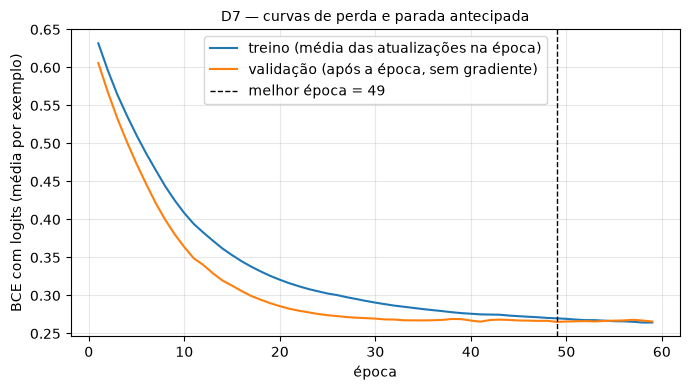

In [14]:
def treinar_com_early_stopping(modelo, loader_treino, loader_validacao,
                       max_epocas=100, paciencia=10, min_delta=0.0001,
                       otimizador=None, criterio=None, dispositivo='cpu'):
    """Treina monitorando a perda de VALIDAÇÃO e restaura o melhor estado.

    Melhora = perda_val < melhor_perda - min_delta. Ao melhorar, guarda uma cópia
    independente (deepcopy) do state_dict. Para quando `paciencia` épocas seguidas
    não melhoram, ou ao atingir `max_epocas`. Antes de devolver, carrega os melhores pesos.
    O loader de teste não é parâmetro desta função.
    """
    otimizador = otimizador or torch.optim.Adam(modelo.parameters(), lr=1e-3)
    criterio = criterio or nn.BCEWithLogitsLoss()
    melhor_perda, melhor_epoca, melhor_estado, sem_melhora = float('inf'), 0, None, 0
    historico, motivo = [], f'máximo de épocas ({max_epocas}) atingido antes da paciência'
    for epoca in range(1, max_epocas + 1):
        perda_tr = treinar_epoca(modelo, loader_treino, otimizador, criterio, dispositivo)
        perda_val = avaliar_perda(modelo, loader_validacao, criterio, dispositivo)
        melhorou = perda_val < melhor_perda - min_delta
        if melhorou:
            melhor_perda, melhor_epoca, sem_melhora = perda_val, epoca, 0
            melhor_estado = copy.deepcopy(modelo.state_dict())
        else:
            sem_melhora += 1
        historico.append({'epoca': epoca, 'perda_treino': perda_tr, 'perda_validacao': perda_val,
                          'melhorou': melhorou, 'epocas_sem_melhora': sem_melhora})
        if sem_melhora >= paciencia:
            motivo = f'paciência esgotada ({paciencia} épocas sem melhora > {min_delta})'
            break
    estado_ultima_epoca = copy.deepcopy(modelo.state_dict())
    modelo.load_state_dict(melhor_estado)
    return {'historico': pd.DataFrame(historico), 'melhor_epoca': melhor_epoca, 'epoca_final': epoca,
            'melhor_perda': melhor_perda, 'motivo': motivo, 'estado_ultima_epoca': estado_ultima_epoca}

# Configuração declarada antes do treino (referência do enunciado)
D_MAX_EPOCAS, D_PACIENCIA, D_MIN_DELTA, D_LR = 100, 10, 1e-4, 1e-3
fixar_semente(SEED)
modelo_final = criar_modelo(11, batchnorm=False).to(DISPOSITIVO)      # rede nova, sem nada da Parte C
otimizador_final = torch.optim.Adam(modelo_final.parameters(), lr=D_LR)
criterio_final = nn.BCEWithLogitsLoss()                                 # sem ponderação de classes
loader_treino.generator.manual_seed(SEED)
saida_d7 = treinar_com_early_stopping(modelo_final, loader_treino, loader_validacao, D_MAX_EPOCAS,
                              D_PACIENCIA, D_MIN_DELTA, otimizador_final, criterio_final, DISPOSITIVO)
historico = saida_d7['historico']
historico.to_csv(RESULTADOS / 'd7_historico.csv', index=False)
print(f"Melhor época: {saida_d7['melhor_epoca']} | época final: {saida_d7['epoca_final']} "
      f"| melhor perda val: {saida_d7['melhor_perda']:.5f}\nMotivo da parada: {saida_d7['motivo']}")
print(historico.iloc[np.r_[0:3, saida_d7['melhor_epoca'] - 2:saida_d7['melhor_epoca'] + 1, -3:0]]
      .drop_duplicates().round(5).to_string(index=False))

# Confirmação da restauração
perda_restaurada = avaliar_perda(modelo_final, loader_validacao, criterio_final, DISPOSITIVO)
perda_ultima = historico.perda_validacao.iloc[-1]
dif_pesos = sum((saida_d7['estado_ultima_epoca'][k] - v).abs().sum().item()
                for k, v in modelo_final.state_dict().items())
print(f'Perda val após restaurar: {perda_restaurada:.5f} (igual à melhor: '
      f'{np.isclose(perda_restaurada, saida_d7["melhor_perda"])}) | perda val da última época: {perda_ultima:.5f}')
print(f'Soma |pesos restaurados − pesos da última época|: {dif_pesos:.4f}')
assert np.isclose(perda_restaurada, saida_d7['melhor_perda'], atol=1e-6)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(historico.epoca, historico.perda_treino, label='treino (média das atualizações na época)')
ax.plot(historico.epoca, historico.perda_validacao, label='validação (após a época, sem gradiente)')
ax.axvline(saida_d7['melhor_epoca'], ls='--', c='k', lw=1, label=f"melhor época = {saida_d7['melhor_epoca']}")
ax.set_xlabel('época'); ax.set_ylabel('BCE com logits (média por exemplo)')
ax.set_title('D7 — curvas de perda e parada antecipada', fontsize=10)
ax.legend(); ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(RESULTADOS / 'd7_curvas_perda.png', dpi=150)
plt.show()

## D4. Custos como hipóteses explícitas
Descreva a ação de selecionar uma amostra como alta nota. Defina custos positivos de falso positivo e falso negativo, uma unidade e uma justificativa. Não existem custos reais no CSV. Acertos custam zero na simplificação deste laboratório.

In [15]:
# Ação: prever positivo = SELECIONAR a amostra para a análise especial de alta nota.
#       prever negativo = não selecionar (segue o fluxo comum).
# Custos HIPOTÉTICOS do exercício — o CSV não contém preços, perdas ou custos reais.
UNIDADE_CUSTO = 'unidades de custo hipotético (u.c.)'
C_FP = 1.0   # FP: uma análise especial gasta numa amostra com nota < 7 (esforço desperdiçado = 1 análise)
C_FN = 3.0   # FN: uma amostra de nota >= 7 deixada de fora; supomos que perder um vinho bom
             # (oportunidade de lote premium) custa o equivalente a 3 análises desperdiçadas.
assert C_FP > 0 and C_FN > 0
matriz_custos = pd.DataFrame([[0, C_FP], [C_FN, 0]], index=['real 0 (nota<7)', 'real 1 (nota>=7)'],
                             columns=['previsto 0 (não seleciona)', 'previsto 1 (seleciona)'])
print('Matriz de custos (' + UNIDADE_CUSTO + '); acertos custam 0:\n' + matriz_custos.to_string())
print('Limiar teórico C_FP/(C_FP+C_FN) =', C_FP / (C_FP + C_FN))

Matriz de custos (unidades de custo hipotético (u.c.)); acertos custam 0:
                  previsto 0 (não seleciona)  previsto 1 (seleciona)
real 0 (nota<7)                          0.0                     1.0
real 1 (nota>=7)                         3.0                     0.0
Limiar teórico C_FP/(C_FP+C_FN) = 0.25


## D5 e D6. Escolha na validação e fórmula
Use `obter_escores(modelo_final, loader_validacao, DISPOSITIVO)` após a restauração. Compare limiares usando os rótulos da validação. Inclua os casos extremos; registre regra de empate ou resolução de uma grade. Compare com 0,5 e com `C_FP/(C_FP+C_FN)`. Investigue calibração sem transformar sigmoide em garantia de probabilidade.

Salve modelo, normalização, lista de entradas, custos e limiar como escolhas fixadas antes da próxima seção.

274 limiares avaliados; 1 empatados no custo mínimo 60.0
                   regra  limiar  tp  fp  fn  tn  selecionados  custo_total  custo_medio
  escolhido na validação  0.2766  24  33   9 252            57         60.0       0.1887
              padrão 0,5  0.5000   8  12  25 273            20         87.0       0.2736
fórmula C_FP/(C_FP+C_FN)  0.2500  24  35   9 250            59         62.0       0.1950
          seleciona tudo  0.0000  33 285   0   0           318        285.0       0.8962
      não seleciona nada     inf   0   0  33 285             0         99.0       0.3113

Brier (validação): 0.0790 | Brier de um escore constante = prevalência: 0.0930
Média dos escores: 0.1269 | prevalência da validação: 0.1038
 escore_medio_no_bin  fracao_positiva_observada
              0.0050                     0.0000
              0.0095                     0.0000
              0.0176                     0.0263
              0.0307                     0.0750
              0.0685        

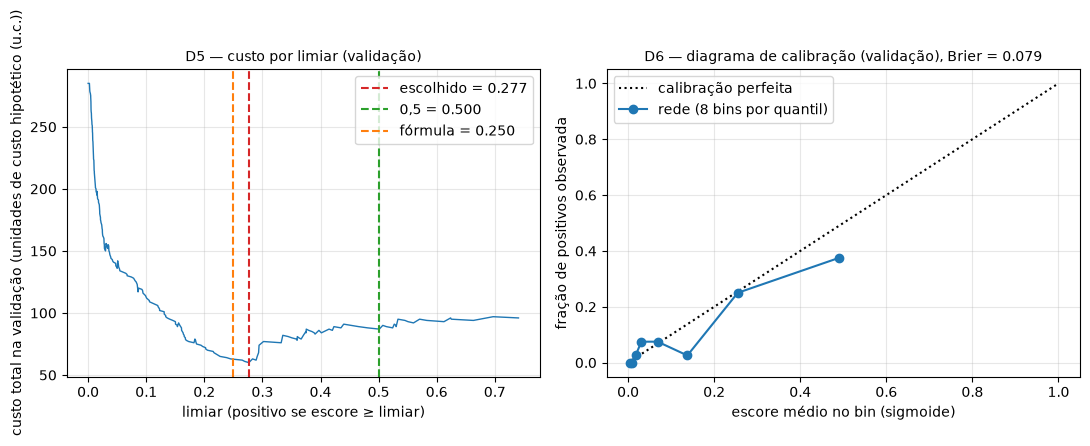


Decisão congelada: limiar = 0.276610 (fórmula = 0.25, padrão = 0,5)


In [16]:
limiar_validacao = None
decisao_congelada = False

y_val, s_val = obter_escores(modelo_final, loader_validacao, DISPOSITIVO)   # modelo já restaurado
assert np.array_equal(y_val, ds_validacao.y.numpy().astype(int))           # ordem preservada

def custos_no_limiar(y, s, t):
    pred = (s >= t).astype(int)
    fp = int(((pred == 1) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    tp = int(((pred == 1) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    custo = C_FP * fp + C_FN * fn
    return {'limiar': t, 'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn, 'selecionados': int(pred.sum()),
            'custo_total': custo, 'custo_medio': custo / len(y)}

# Candidatos: todos os escores únicos da validação + extremos
# 0.0 → todos positivos (seleciona tudo); +inf → todos negativos (nenhuma seleção). Busca exata, sem grade.
candidatos = np.unique(np.concatenate([[0.0], s_val, [np.inf]]))
busca = pd.DataFrame([custos_no_limiar(y_val, s_val, t) for t in candidatos])
custo_min = busca.custo_total.min()
# Regra de desempate (fixada antes): entre custos mínimos iguais, o MAIOR limiar
# (menos amostras selecionadas → menos análises com o mesmo custo esperado).
empatados = busca[np.isclose(busca.custo_total, custo_min)]
limiar_validacao = float(empatados.limiar.max())
print(f'{len(candidatos)} limiares avaliados; {len(empatados)} empatados no custo mínimo {custo_min:.1f}')

limiar_formula = C_FP / (C_FP + C_FN)
comparacao_val = pd.DataFrame([
    {'regra': 'escolhido na validação', **custos_no_limiar(y_val, s_val, limiar_validacao)},
    {'regra': 'padrão 0,5', **custos_no_limiar(y_val, s_val, 0.5)},
    {'regra': 'fórmula C_FP/(C_FP+C_FN)', **custos_no_limiar(y_val, s_val, limiar_formula)},
    {'regra': 'seleciona tudo', **custos_no_limiar(y_val, s_val, 0.0)},
    {'regra': 'não seleciona nada', **custos_no_limiar(y_val, s_val, np.inf)},
])
print(comparacao_val.round(4).to_string(index=False))
busca.to_csv(RESULTADOS / 'd5_busca_limiar_validacao.csv', index=False)
comparacao_val.to_csv(RESULTADOS / 'd5_comparacao_validacao.csv', index=False)

# ---- D6: calibração na validação (apoio à discussão, não prova) ----
brier_val = brier_score_loss(y_val, s_val)
print(f'\nBrier (validação): {brier_val:.4f} | Brier de um escore constante = prevalência: '
      f'{brier_score_loss(y_val, np.full_like(s_val, y_val.mean())):.4f}')
print(f'Média dos escores: {s_val.mean():.4f} | prevalência da validação: {y_val.mean():.4f}')
frac_pos, media_esc = calibration_curve(y_val, s_val, n_bins=8, strategy='quantile')
tabela_calib = pd.DataFrame({'escore_medio_no_bin': media_esc, 'fracao_positiva_observada': frac_pos}).round(4)
print(tabela_calib.to_string(index=False))

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
b = busca[np.isfinite(busca.limiar)]
axs[0].plot(b.limiar, b.custo_total, lw=1)
for t, c, nome in [(limiar_validacao, 'C3', 'escolhido'), (0.5, 'C2', '0,5'), (limiar_formula, 'C1', 'fórmula')]:
    axs[0].axvline(t, color=c, ls='--', label=f'{nome} = {t:.3f}')
axs[0].set_xlabel('limiar (positivo se escore ≥ limiar)'); axs[0].set_ylabel(f'custo total na validação ({UNIDADE_CUSTO})')
axs[0].set_title('D5 — custo por limiar (validação)', fontsize=10); axs[0].legend(); axs[0].grid(alpha=.3)
axs[1].plot([0, 1], [0, 1], 'k:', label='calibração perfeita')
axs[1].plot(media_esc, frac_pos, 'o-', label='rede (8 bins por quantil)')
axs[1].set_xlabel('escore médio no bin (sigmoide)'); axs[1].set_ylabel('fração de positivos observada')
axs[1].set_title(f'D6 — diagrama de calibração (validação), Brier = {brier_val:.3f}', fontsize=10)
axs[1].legend(); axs[1].grid(alpha=.3)
fig.tight_layout(); fig.savefig(RESULTADOS / 'd5_d6_custo_calibracao.png', dpi=150); plt.show()

# ---- Congelamento: tudo fixado ANTES de abrir o teste ----
torch.save(modelo_final.state_dict(), RESULTADOS / 'modelo_final.pt')
decisao = {
    'features': FEATURES, 'normalizacao': {'convencao': 'z-score, desvio ddof=0, estatísticas do treino',
                                           'media': ds_treino.media.tolist(), 'desvio': ds_treino.desvio.tolist()},
    'modelo': 'criar_modelo(11, batchnorm=False) — 11→16→ReLU→1; pesos em resultados/modelo_final.pt',
    'treino': {'otimizador': f'Adam lr={D_LR}', 'perda': 'BCEWithLogitsLoss sem ponderação', 'lote': LOTE_TREINO,
               'max_epocas': D_MAX_EPOCAS, 'paciencia': D_PACIENCIA, 'min_delta': D_MIN_DELTA,
               'melhor_epoca': saida_d7['melhor_epoca'], 'semente': SEED},
    'custos': {'C_FP': C_FP, 'C_FN': C_FN, 'unidade': UNIDADE_CUSTO, 'natureza': 'hipotéticos'},
    'limiar_escolhido': limiar_validacao, 'regra': 'positivo se escore >= limiar',
    'desempate': 'maior limiar entre custos mínimos iguais', 'limiar_formula': limiar_formula,
}
(RESULTADOS / 'decisao_congelada.json').write_text(json.dumps(decisao, indent=2, ensure_ascii=False))
decisao_congelada = True
print(f'\nDecisão congelada: limiar = {limiar_validacao:.6f} (fórmula = {limiar_formula}, padrão = 0,5)')

## D1, D2 e D3. Avaliação final
Só agora obtenha escores no teste com o modelo restaurado e decisão congelada. Avalie as duas regras já fixadas (0,5 e limiar escolhido). O baseline usa a classe majoritária **do treino**. Produza matriz com ordem `[0, 1]`, métricas, prevalência e custos.

AUC-ROC e AUC-PR usam escores. Com `precision_recall_curve`, calcule a área trapezoidal usando `auc(recall, precision)`; se reportar `average_precision_score`, chame-a AP. Na ROC, desenhe a diagonal aleatória. Na PR, desenhe a prevalência do teste.

Não use o resultado do teste para voltar à busca. Relate os limites observados.

Teste: 320 observações | positivos 45 | prevalência 0.1406
Classe majoritária no treino: 0

Matriz de confusão — Trivial do treino (classe 0) (linhas = real, colunas = previsto, ordem [0, 1]):
        previsto 0  previsto 1
real 0         275           0
real 1          45           0

Matriz de confusão — Rede: padrão (linhas = real, colunas = previsto, ordem [0, 1]):
        previsto 0  previsto 1
real 0         269           6
real 1          33          12

Matriz de confusão — Rede: escolhido na validação (linhas = real, colunas = previsto, ordem [0, 1]):
        previsto 0  previsto 1
real 0         246          29
real 1          17          28

                       regra        limiar  acuracia  precisao  revocacao    f1  auc_roc  auc_pr_trapezio     ap  tp  fp  fn  tn  custo_total  custo_por_obs
Trivial do treino (classe 0) não se aplica    0.8594    0.0000     0.0000 0.000      NaN              NaN    NaN   0   0  45 275        135.0         0.4219
                Rede: pad


Intervalos bootstrap (percentil, teste):
                     IC95_inf  IC95_sup
auc_roc                0.8479    0.9296
revocacao_escolhido    0.4808    0.7674
precisao_escolhido     0.3684    0.6212
custo_obs_escolhido    0.1781    0.3344
custo_obs_05           0.2343    0.4312


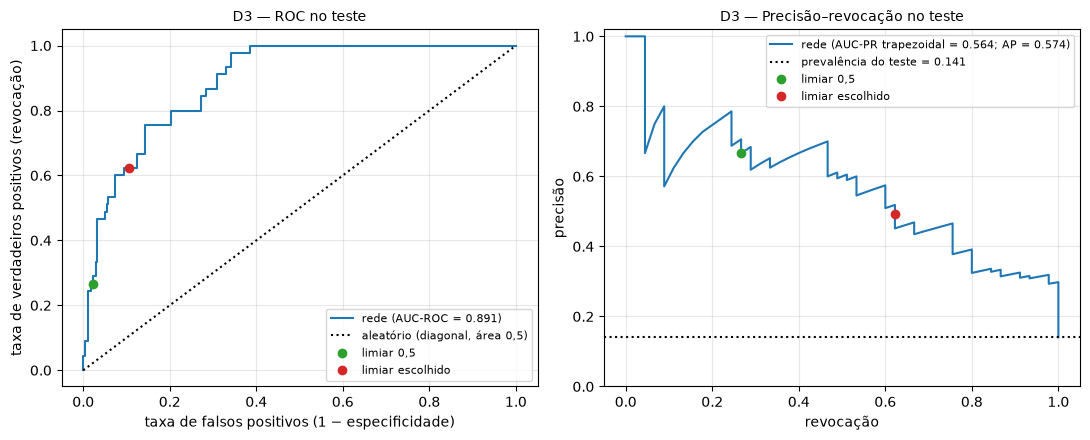

In [17]:
avaliacao_final = None
if not decisao_congelada:
    print('Avaliação final pendente: concluir o desenvolvimento e congelar a decisão.')
else:
    # Escores do teste obtidos UMA vez, com o modelo restaurado e a decisão já gravada.
    alvo_teste, probas_teste = obter_escores(modelo_final, loader_teste, DISPOSITIVO)
    assert np.array_equal(alvo_teste, ds_teste.y.numpy().astype(int))
    prevalencia_teste = alvo_teste.mean()
    classe_majoritaria = int(particoes_grupo['treino'].alvo.value_counts().idxmax())   # do TREINO
    print(f'Teste: {len(alvo_teste)} observações | positivos {alvo_teste.sum()} | prevalência {prevalencia_teste:.4f}')
    print('Classe majoritária no treino:', classe_majoritaria)

    def relatorio(nome, limiar_txt, pred, escores=None):
        matriz_confusao = np.array([
                    [np.count_nonzero((alvo_teste == 0) & (pred == 0)), np.count_nonzero((alvo_teste == 0) & (pred == 1))],
                    [np.count_nonzero((alvo_teste == 1) & (pred == 0)), np.count_nonzero((alvo_teste == 1) & (pred == 1))],
                ], dtype=int)
        tn, fp, fn, tp = matriz_confusao.ravel()
        custo = C_FP * fp + C_FN * fn
        linha = {'regra': nome, 'limiar': limiar_txt,
                 'acuracia': accuracy_score(alvo_teste, pred),
                 'precisao': precision_score(alvo_teste, pred, zero_division=0),   # 0 se nenhum positivo previsto
                 'revocacao': recall_score(alvo_teste, pred, zero_division=0),
                 'f1': f1_score(alvo_teste, pred, zero_division=0),
                 'auc_roc': roc_auc_score(alvo_teste, escores) if escores is not None else np.nan,
                 'auc_pr_trapezio': np.nan, 'ap': np.nan,
                 'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
                 'custo_total': custo, 'custo_por_obs': custo / len(alvo_teste)}
        if escores is not None:
            p, r, _ = precision_recall_curve(alvo_teste, escores)
            linha['auc_pr_trapezio'] = auc(r, p)
            linha['ap'] = average_precision_score(alvo_teste, escores)
        mat = pd.DataFrame(matriz_confusao, index=['real 0', 'real 1'], columns=['previsto 0', 'previsto 1'])
        return linha, mat

    pred_trivial = np.full_like(alvo_teste, classe_majoritaria)
    pred_050 = (probas_teste >= 0.5).astype(int)
    pred_escolhido = (probas_teste >= limiar_validacao).astype(int)
    linhas, matrizes = [], {}
    for nome, lim, pred, esc in [('Trivial do treino (classe %d)' % classe_majoritaria, 'não se aplica', pred_trivial, None),
                                 ('Rede: padrão', '0,5', pred_050, probas_teste),
                                 ('Rede: escolhido na validação', f'{limiar_validacao:.4f}', pred_escolhido, probas_teste)]:
        linha, mat = relatorio(nome, lim, pred, esc)
        linhas.append(linha); matrizes[nome] = mat
    tabela_final = pd.DataFrame(linhas)
    for nome, mat in matrizes.items():
        print(f'\nMatriz de confusão — {nome} (linhas = real, colunas = previsto, ordem [0, 1]):\n{mat.to_string()}')
        slug = 'trivial' if nome.startswith('Trivial') else ('limiar_05' if 'padrão' in nome else 'limiar_escolhido')
        mat.to_csv(RESULTADOS / f'd1_matriz_{slug}.csv')
    print('\n' + tabela_final.round(4).to_string(index=False))
    tabela_final.to_csv(RESULTADOS / 'd2_tabela_final_teste.csv', index=False)

    # Incerteza amostral do teste (bootstrap 2000×; só descreve, não escolhe nada)
    rng = np.random.default_rng(SEED)
    boot = []
    for _ in range(2000):
        i = rng.integers(0, len(alvo_teste), len(alvo_teste))
        if alvo_teste[i].min() == alvo_teste[i].max():
            continue
        boot.append({'auc_roc': roc_auc_score(alvo_teste[i], probas_teste[i]),
                     'revocacao_escolhido': recall_score(alvo_teste[i], pred_escolhido[i], zero_division=0),
                     'precisao_escolhido': precision_score(alvo_teste[i], pred_escolhido[i], zero_division=0),
                     'custo_obs_escolhido': (C_FP * ((pred_escolhido[i] == 1) & (alvo_teste[i] == 0)).sum()
                                             + C_FN * ((pred_escolhido[i] == 0) & (alvo_teste[i] == 1)).sum()) / len(i),
                     'custo_obs_05': (C_FP * ((pred_050[i] == 1) & (alvo_teste[i] == 0)).sum()
                                      + C_FN * ((pred_050[i] == 0) & (alvo_teste[i] == 1)).sum()) / len(i)})
    ic = pd.DataFrame(boot).quantile([0.025, 0.975]).T.round(4)
    ic.columns = ['IC95_inf', 'IC95_sup']
    print('\nIntervalos bootstrap (percentil, teste):\n' + ic.to_string())
    ic.to_csv(RESULTADOS / 'd2_bootstrap_teste.csv')

    # D3 — curvas
    fpr, tpr, _ = roc_curve(alvo_teste, probas_teste)
    prec, rec, _ = precision_recall_curve(alvo_teste, probas_teste)
    auc_roc_t, auc_pr_t = tabela_final.auc_roc.iloc[1], tabela_final.auc_pr_trapezio.iloc[1]
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
    axs[0].plot(fpr, tpr, label=f'rede (AUC-ROC = {auc_roc_t:.3f})')
    axs[0].plot([0, 1], [0, 1], 'k:', label='aleatório (diagonal, área 0,5)')
    axs[0].set_xlabel('taxa de falsos positivos (1 − especificidade)'); axs[0].set_ylabel('taxa de verdadeiros positivos (revocação)')
    axs[0].set_title('D3 — ROC no teste', fontsize=10)
    axs[1].plot(rec, prec, label=f'rede (AUC-PR trapezoidal = {auc_pr_t:.3f}; AP = {tabela_final.ap.iloc[1]:.3f})')
    axs[1].axhline(prevalencia_teste, color='k', ls=':', label=f'prevalência do teste = {prevalencia_teste:.3f}')
    axs[1].set_xlabel('revocação'); axs[1].set_ylabel('precisão'); axs[1].set_ylim(0, 1.02)
    axs[1].set_title('D3 — Precisão–revocação no teste', fontsize=10)
    for t, c, nome in [(0.5, 'C2', '0,5'), (limiar_validacao, 'C3', 'escolhido')]:
        pr_ = precision_score(alvo_teste, probas_teste >= t, zero_division=0); rc_ = recall_score(alvo_teste, probas_teste >= t)
        fp_ = ((probas_teste >= t) & (alvo_teste == 0)).sum() / (alvo_teste == 0).sum()
        axs[0].plot(fp_, rc_, 'o', color=c, label=f'limiar {nome}')
        axs[1].plot(rc_, pr_, 'o', color=c, label=f'limiar {nome}')
    for ax in axs:
        ax.legend(fontsize=8); ax.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(RESULTADOS / 'd3_roc_pr_teste.png', dpi=150); plt.show()
    avaliacao_final = {'tabela': tabela_final, 'matrizes': matrizes, 'bootstrap': ic}

## D8. Recomendação final
Escreva no README o parágrafo para quem decide: ação, limiar, evidência final, custos hipotéticos, riscos e limitações. Cite o conjunto avaliado. Não reivindique desempenho em novos produtores, regiões ou datas não observados.

## Conferência da entrega
Reinicie o kernel e execute tudo. O notebook preenchido deve mostrar as saídas de todas as partes; pendências não são resultados. Preencha o README e o arquivo obrigatório de uso de IA. Inclua as referências e registre alterações no apoio.

In [18]:
pendencias = []
for nome, valor in [('particoes', particoes_grupo), ('ds_treino', ds_treino),
    ('loader_treino', loader_treino), ('historico', historico),
    ('limiar_escolhido', limiar_validacao), ('avaliacao_final', avaliacao_final)]:
    if valor is None:
        pendencias.append(nome)
if not tempos: pendencias.append('tempos A3')
if len(resultados_c) < 2: pendencias.append('dois resultados C')
print('Pendências estruturais:', pendencias)
print('Esta checagem não corrige a análise nem substitui o checklist do enunciado.')

Pendências estruturais: []
Esta checagem não corrige a análise nem substitui o checklist do enunciado.
